# House Price Prediction ML Project

**Project Problem Statement**

* A real-estate company wants to predict the selling price of a house based on its features such as area, number of bedrooms, bathrooms, location, and other property characteristics. 
* The goal is to estimate the expected house price for a new property.

**or:**

`Objective`

To build an accurate machine learning pipeline that predicts house price using structural, temporal, and spatial features.

`Core Challenges`

* Skewed Data: Extreme luxury house prices skew the target variable and confuse basic models.
* Mixed Layouts: Features contain both highly skewed continuous numbers (sqft_living, yr_built) and text categories (Condition_Label).
* Feature Noise: Redundant metrics can slow down training and cause overfitting.

`The Solution`
* Clean outliers using IQR, 
* normalize skewed data via Log/Power transforms, 
* automate processing with Pipelines to prevent data leakage

**Step 1: Import Libraries**

In [209]:
# data handling 
import joblib
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# feature selection
from sklearn.feature_selection import VarianceThreshold

# metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

**Step 2: Load Dataset**

In [210]:
df = pd.read_csv('kc_house_data.csv')

**Step 3: Understand Your Data (EDA)**

In [211]:
print("\n[First 5 Rows]:\n")
df.head()


[First 5 Rows]:



,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [212]:
print(f"\n[Shape of Dataset]: {df.shape}")


[Shape of Dataset]: (21613, 21)


In [213]:
print("\n[Info Structural Check]:")
df.info()


[Info Structural Check]:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  floa

In [214]:
print("\n[Data Types]:\n") 
df.dtypes


[Data Types]:



id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [215]:
print("\n[Descriptive Statistics]:\n") 
df.describe().T


[Descriptive Statistics]:



,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


In [216]:
# Target Variable Analysis (Price)
print(f"\n[Target Skewness Before Transformation]: {df['price'].skew():.2f}")


[Target Skewness Before Transformation]: 4.02


**Step 4: Data Cleaning**

In [217]:
# 1. Remove Duplicates
print(f"Duplicates found: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicates found: 0


In [218]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [219]:
# 2. Remove Unwanted Columns
df.drop(columns=["id"], inplace=True)

In [220]:
df.drop(columns=["waterfront","view","yr_renovated"], inplace=True)

In [221]:
# 3. check Missing Values
df.isnull().sum()

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [222]:
# 4. Fix Data Types
df['date'] = pd.to_datetime(df['date'], errors='coerce')

<Axes: >

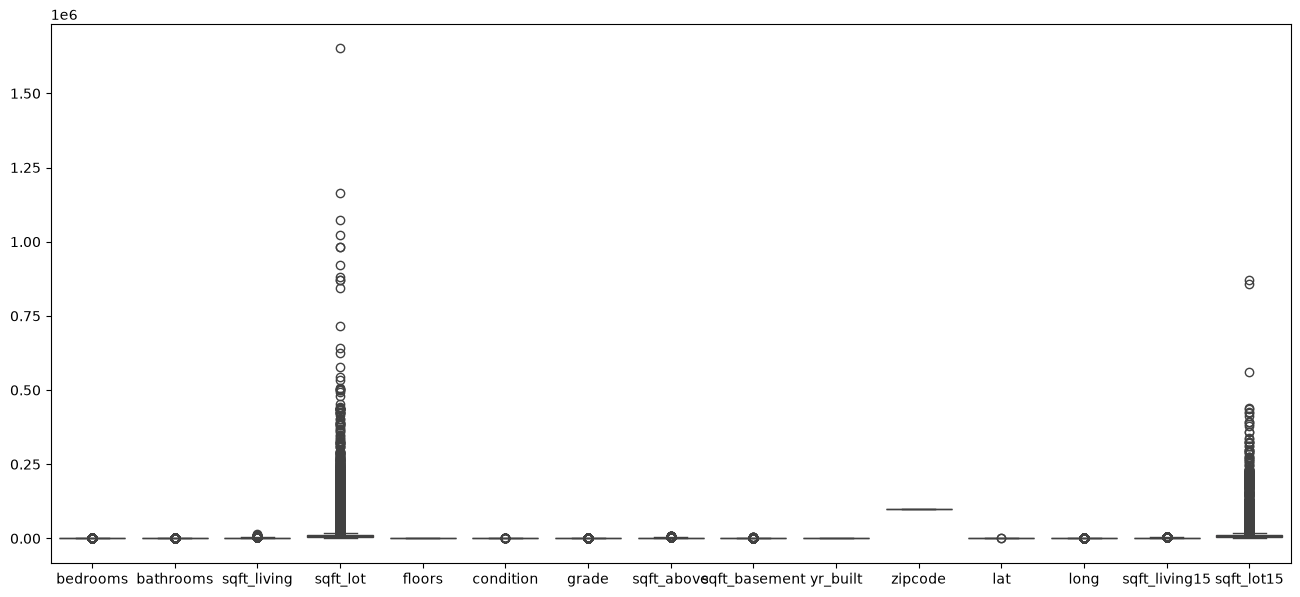

In [223]:
# 5. Outlier Detection and Capping

plt.figure(figsize=(16,7))
sns.boxplot(df[df.select_dtypes(include=[int,float]).drop(columns=['price']).columns.to_list()])

In [224]:
cols = df.select_dtypes(include=[int,float]).drop(columns=['price']).columns.to_list()
for i,col in enumerate(cols, start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{i}. {col}")
    print(f"lower: {lower} | upper: {upper}")
    print(f"before outliers: {len(before_outliers)}")
    print(f"after outliers: {len(after_outliers)}")



1. bedrooms
lower: 1.5 | upper: 5.5
before outliers: 546
after outliers: 0

2. bathrooms
lower: 0.625 | upper: 3.625
before outliers: 571
after outliers: 0

3. sqft_living
lower: -257.5 | upper: 4234.5
before outliers: 572
after outliers: 0

4. sqft_lot
lower: -3432.0 | upper: 19160.0
before outliers: 2425
after outliers: 0

5. floors
lower: -0.5 | upper: 3.5
before outliers: 0
after outliers: 0

6. condition
lower: 1.5 | upper: 5.5
before outliers: 30
after outliers: 0

7. grade
lower: 5.5 | upper: 9.5
before outliers: 1911
after outliers: 0

8. sqft_above
lower: -340.0 | upper: 3740.0
before outliers: 611
after outliers: 0

9. sqft_basement
lower: -840.0 | upper: 1400.0
before outliers: 496
after outliers: 0

10. yr_built
lower: 1882.0 | upper: 2066.0
before outliers: 0
after outliers: 0

11. zipcode
lower: 97905.5 | upper: 98245.5
before outliers: 0
after outliers: 0

12. lat
lower: 47.1605 | upper: 47.9885
before outliers: 2
after outliers: 0

13. long
lower: -122.63250000000001 |

<Axes: >

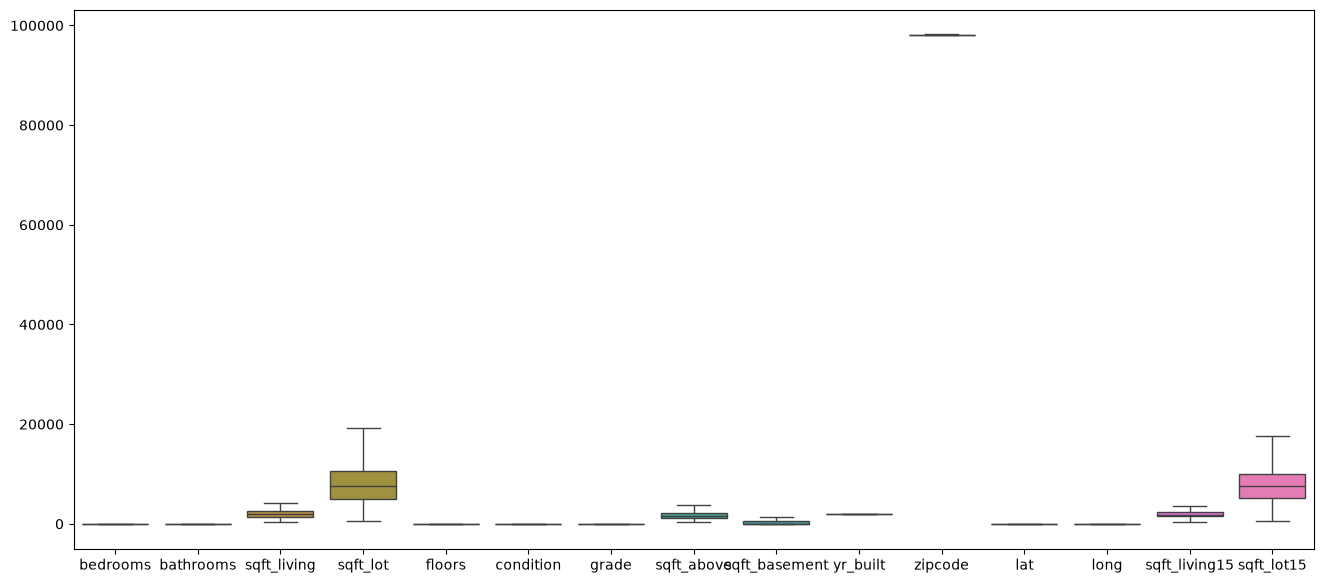

In [225]:
plt.figure(figsize=(16,7))
sns.boxplot(df[df.select_dtypes(include=[int,float]).drop(columns=['price']).columns.to_list()])

**Step 5: Data Visualization**

Univariate:

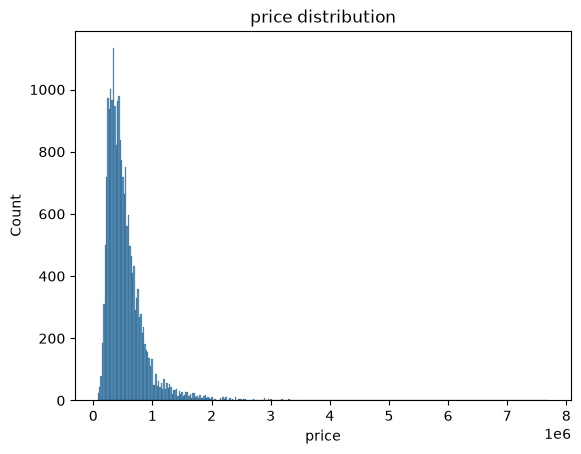

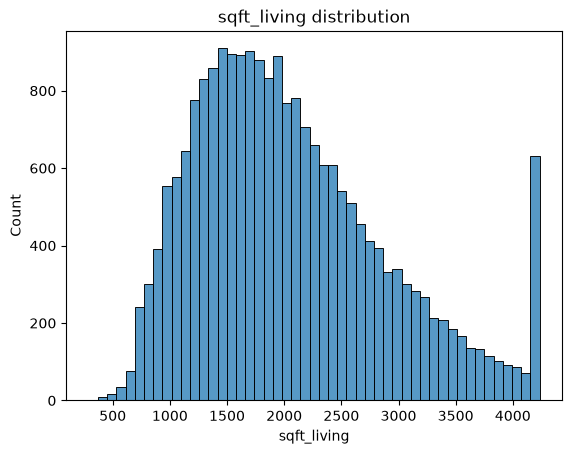

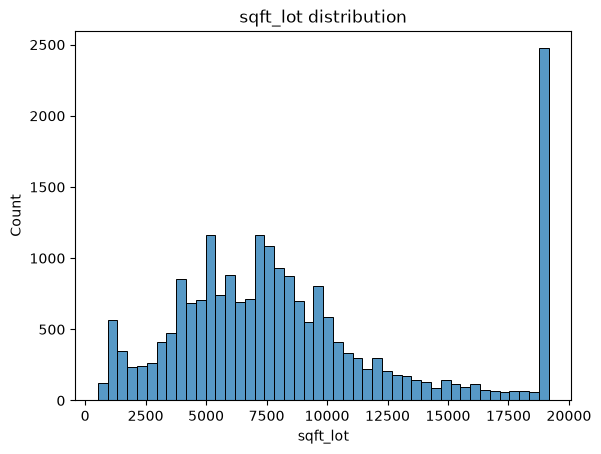

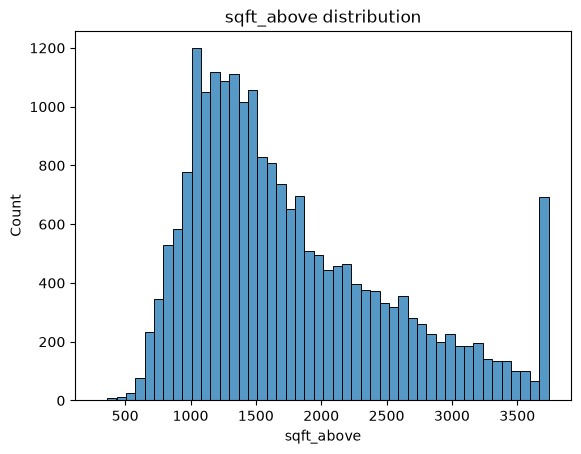

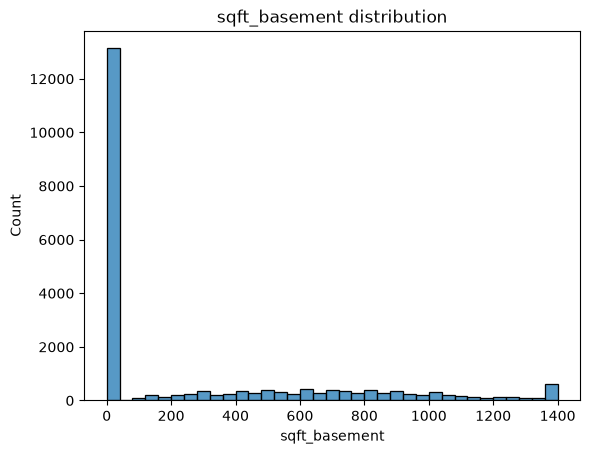

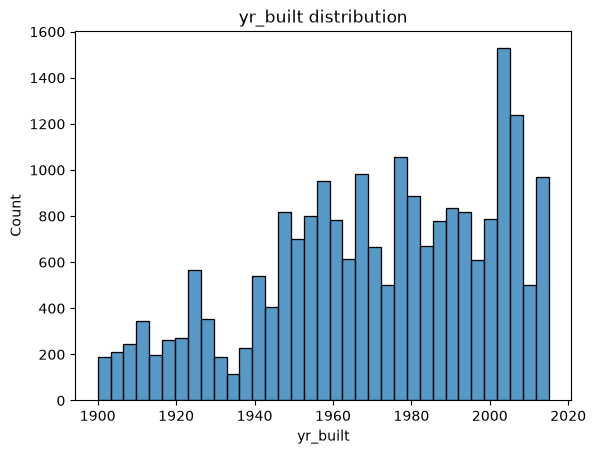

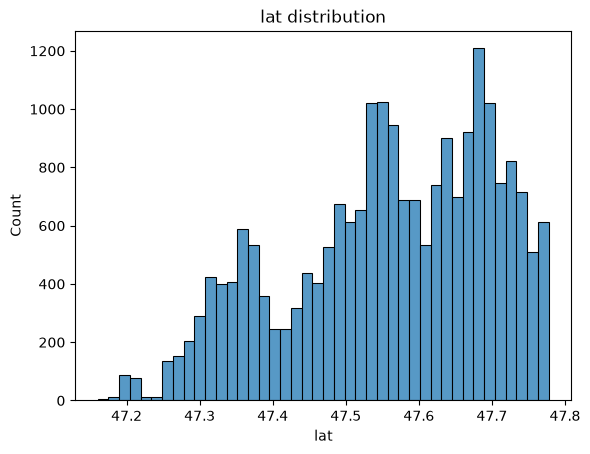

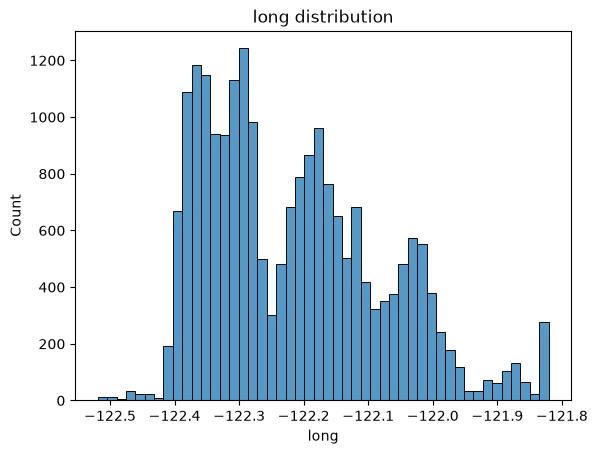

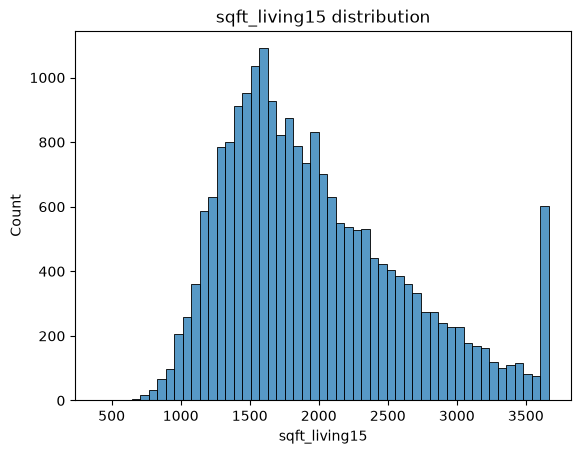

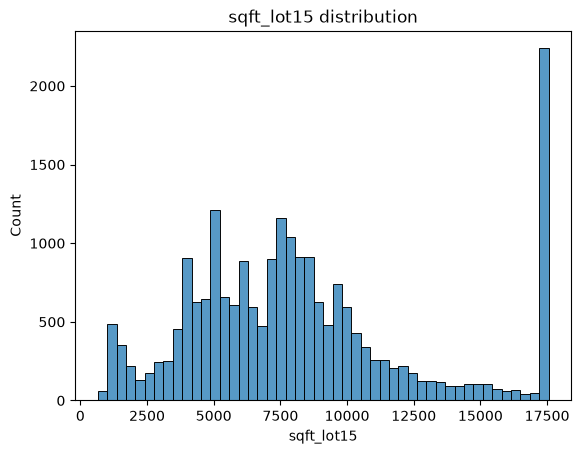

In [226]:
nums = ['price', 'sqft_living', 'sqft_lot','sqft_above','sqft_basement','yr_built','lat','long','sqft_living15','sqft_lot15']
for n in nums:
    sns.histplot(data=df, x=n)
    plt.title(f"{n} distribution")
    plt.show()

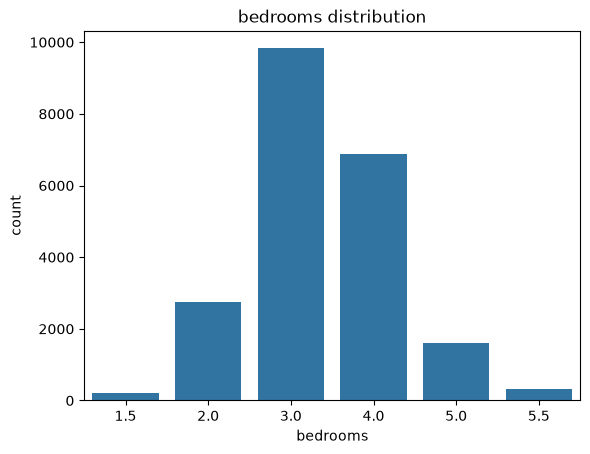

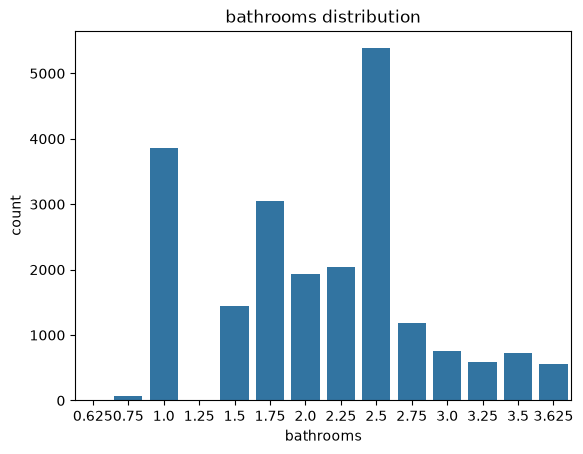

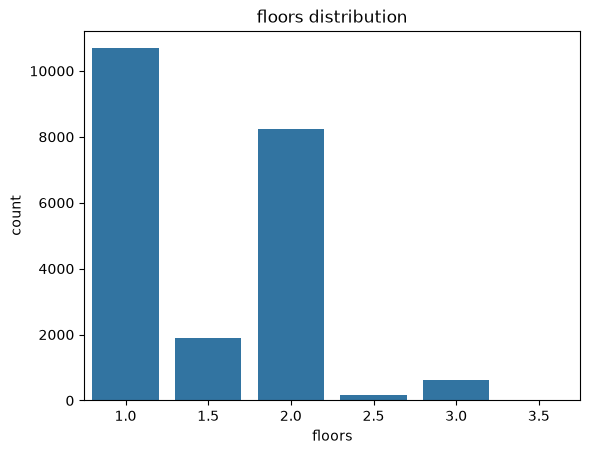

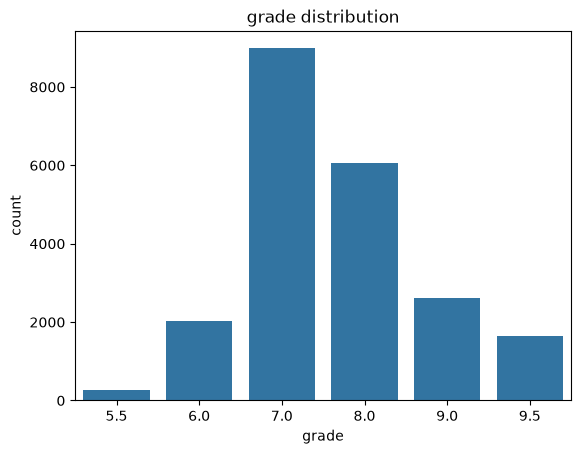

In [227]:
cols = ['bedrooms','bathrooms','floors','grade']
for c in cols:
    sns.countplot(data=df, x=c)     
    plt.title(f"{c} distribution")     
    plt.show()

Bivariate:

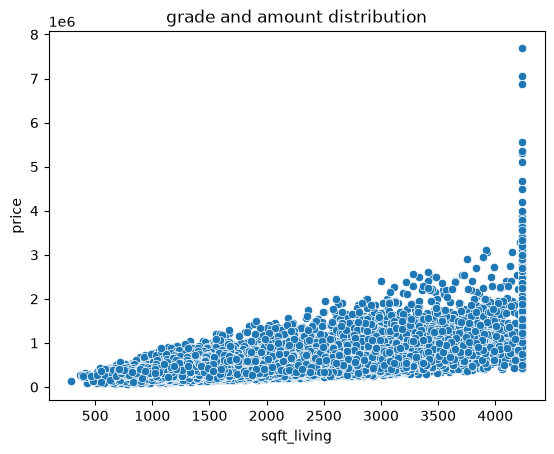

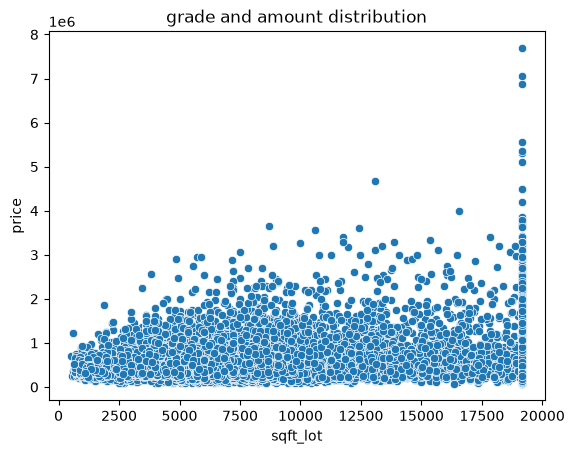

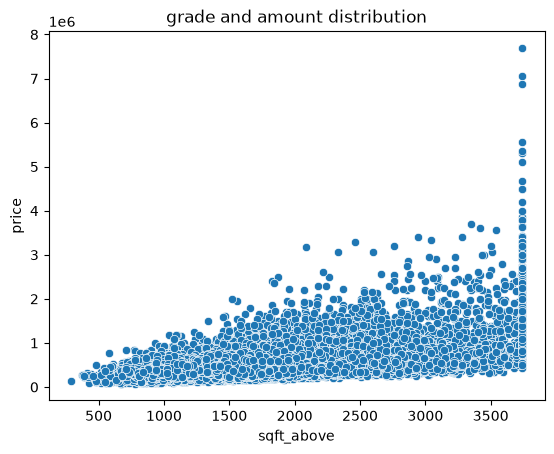

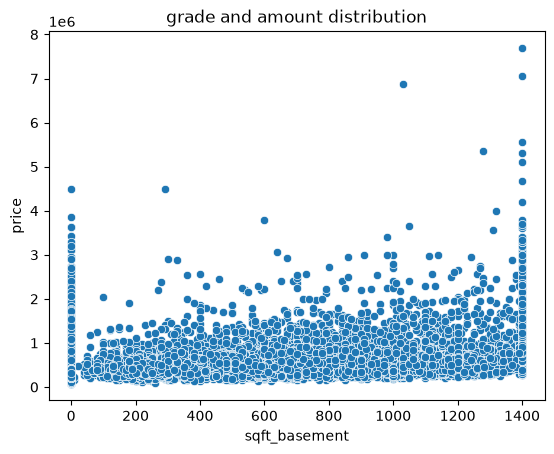

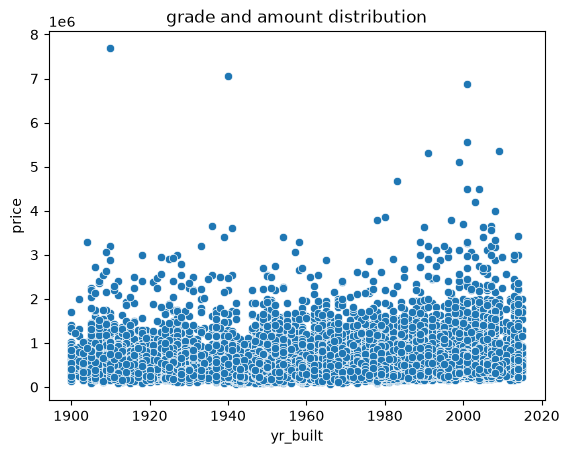

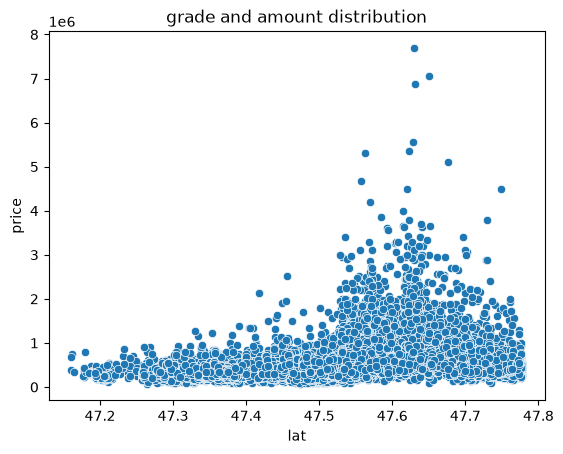

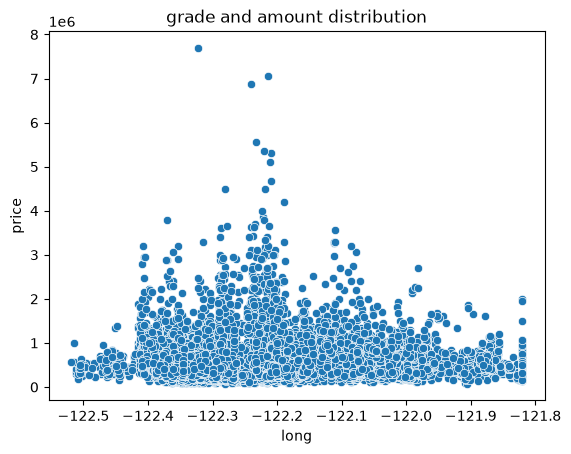

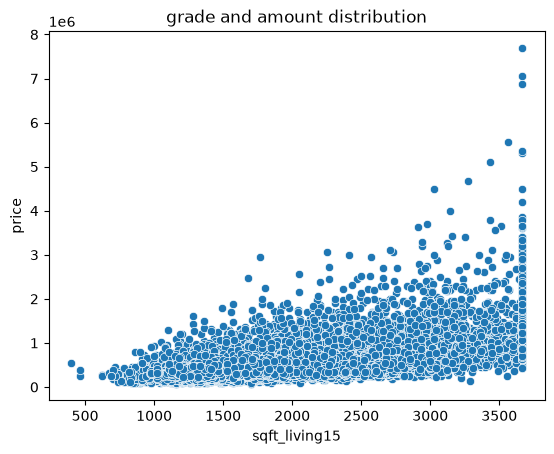

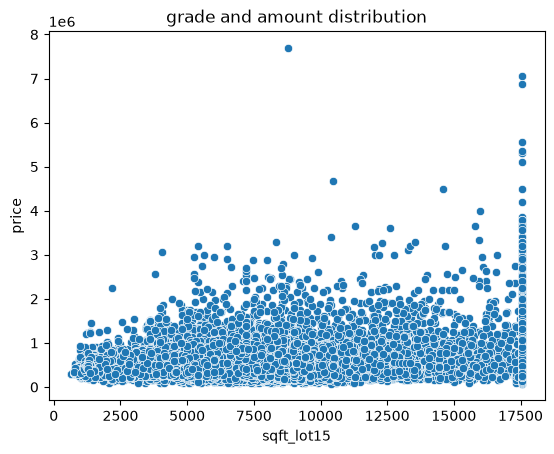

In [228]:
nums = ['sqft_living', 'sqft_lot','sqft_above','sqft_basement','yr_built','lat','long','sqft_living15','sqft_lot15']
for n in nums:
    sns.scatterplot(data=df, x=n, y='price')
    plt.title(f"{c} and amount distribution")
    plt.show()

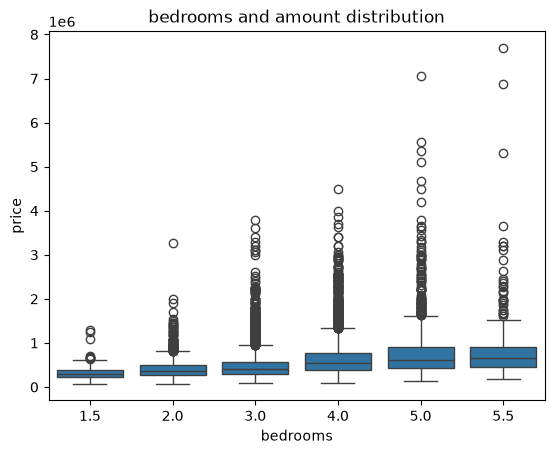

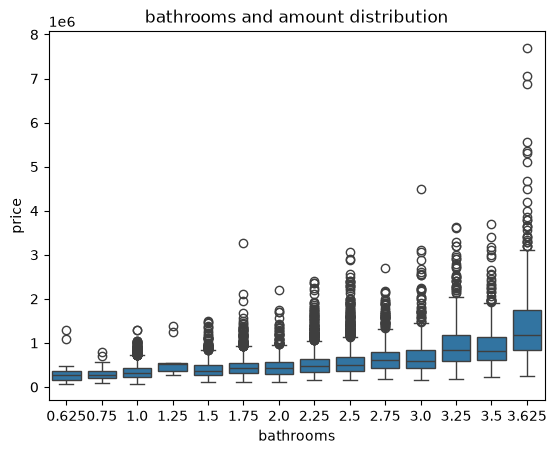

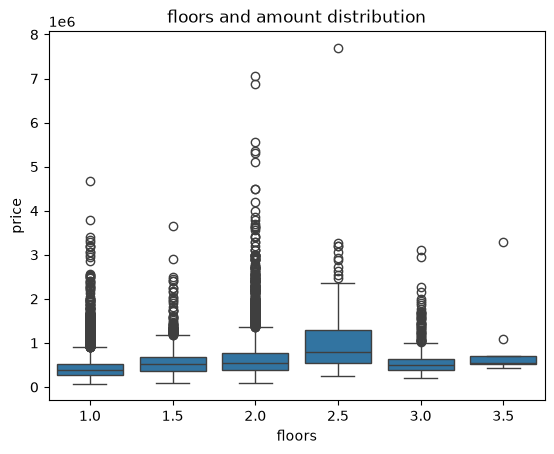

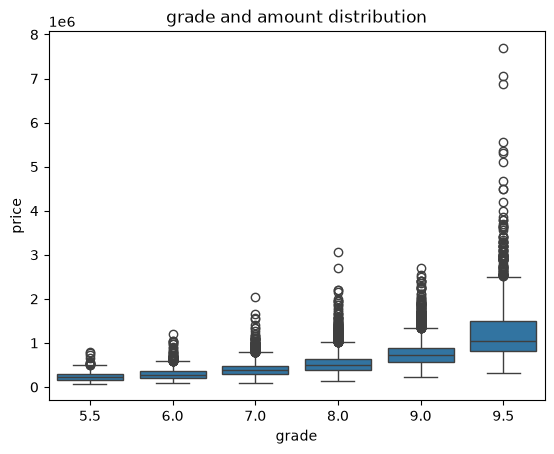

In [229]:
cols = ['bedrooms','bathrooms','floors','grade']
for c in cols:
    sns.boxplot(data=df, x=c, y='price')     
    plt.title(f"{c} and amount distribution")     
    plt.show()

**Correlation matrix:**

Text(0.5, 1.0, 'Correlation matrix')

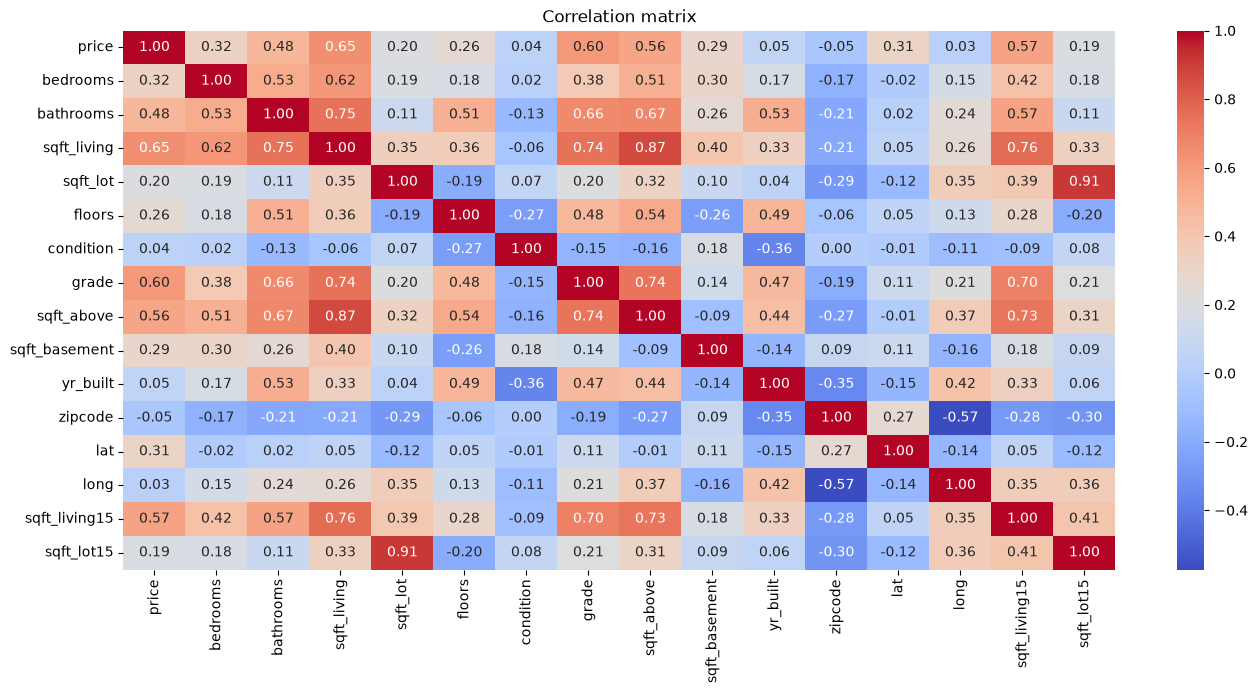

In [230]:
plt.figure(figsize=(16,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation matrix')

**Step 6: Feature Engineering**

In [231]:
df['sale_year'] = pd.to_datetime(df['date']).dt.year
df["HouseAge"] = np.clip(df["sale_year"] - df["yr_built"], 0, None)
df = df.drop(columns=['sale_year'])

df['BedBathRatio'] = df['bathrooms'] / (df['bedrooms'] + 1)
df['LivingLotRatio'] = df['sqft_living'] / (df['sqft_lot'] + 1)

df['Condition_Label'] = df['condition'].map({1:'Poor', 2:'Fair', 3:'Average', 4:'Good', 5:'Luxury'})

# Drop remaining raw columns that are no longer needed
df = df.drop(columns=['date', 'zipcode', 'condition'])

> **right-skewed (using `np.log1p`) and left-skewed data (using `PowerTransformer`)**

```python
# --- CASE 1: RIGHT-SKEWED DATA (e.g., Price, Income) ---
from sklearn.preprocessing import PowerTransformer
y_right_transformed = np.log1p(df['price']) #Accepts 1D column vectors.

#Back to real values
y_right_real = np.expm1(y_right_transformed)

#-----------------------------------------------

# --- CASE 2: LEFT-SKEWED DATA (e.g., Year Built, Scores) ---
pt = PowerTransformer(method='yeo-johnson') #Yeo-Johnson handles left-skew perfectly

y_left_reshaped = df[['yr_built']].values
y_left_transformed = pt.fit_transform(y_left_reshaped) #because it works only on 2D

#Back to real values
y_left_real = pt.inverse_transform(y_left_transformed) 
```

Use np.log1p when:
* The data is **right-skewed**:
* All values are **zero or positive**:
* The outliers **are real**, valid data -> The outliers are data entry errors: If a regular house is listed at $80,000,000 due to a typo, delete the row instead.

**Step 7: Define Features (X) and Target (y)**

In [232]:
X = df.drop(columns=['price'])

# Log-transform transforms right-skewed data into a normal distribution for ML
# calculates the natural logarithm of 1 + x(each element).
y = np.log1p(df['price']) 

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['str', 'category']).columns.tolist()
#num_cols = ['sqft_living', 'sqft_lot','sqft_above','sqft_basement','yr_built','lat','long','sqft_living15','sqft_lot15']
#cat_cols = ['bedrooms','bathrooms','floors','grade']


**Step 8: Train-Test Split**

In [233]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (17290, 17) | X_test Shape: (4323, 17)


**Step 9: Preprocessing Pipeline**

In [234]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    #('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=True)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [235]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

**Step 10: Feature Selection**

In [236]:
# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=0.01)

# Fit and transform the data
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.transform(X_test_processed)

print("X_train shape before feature selection: ",X_train_df.shape)
print("X_train shape after feature selection: ",X_train_sele.shape)
print("\nX_test shape before feature selection: ",X_test_df.shape)
print("X_test shape after feature selection: ",X_test_sele.shape)

X_train shape before feature selection:  (17290, 20)
X_train shape after feature selection:  (17290, 19)

X_test shape before feature selection:  (4323, 20)
X_test shape after feature selection:  (4323, 19)


**Step 11 & 12: Train Models & Regression Metrics**

In [237]:
models = {
    "Linear regression":LinearRegression(),
    "Decision Tree":DecisionTreeRegressor(max_depth=15, min_samples_split=5, min_samples_leaf=3),
    "Gradient Boosting":GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=1200, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=1.5, min_child_weight=3, random_state=42, n_jobs=-1),
    "Random Forest": RandomForestRegressor(n_estimators=500,max_depth=15, max_features='sqrt', min_samples_split=4, min_samples_leaf=2, random_state=42, n_jobs=-1)
}

for name,model in models.items():
    model.fit(X_train_sele,y_train)
    preds_log = model.predict(X_test_sele)
        
    # CRITICAL: Inverse transform predictions back from log space to true dollar values
    y_true_actual = np.expm1(y_test)
    y_pred_actual = np.expm1(preds_log)
    
    r2 = r2_score(y_true_actual, y_pred_actual)
    mae = mean_absolute_error(y_true_actual, y_pred_actual)
    mse = mean_squared_error(y_true_actual, y_pred_actual)
    rmse = np.sqrt(mean_squared_error(y_true_actual, y_pred_actual))
    print(f"[{name}] -> r2: {r2*100:.2f}% | mae: {mae:.2f} | mse: {mse:.2f} | rmse: {rmse:.2f}")
    

[Linear regression] -> r2: 62.64% | mae: 120341.70 | mse: 56480422300.05 | rmse: 237656.10


[Decision Tree] -> r2: 73.13% | mae: 100153.57 | mse: 40625918682.71 | rmse: 201558.72
[Gradient Boosting] -> r2: 84.34% | mae: 76140.68 | mse: 23672111036.50 | rmse: 153857.44
[XGBoost] -> r2: 85.43% | mae: 72921.11 | mse: 22029954089.31 | rmse: 148424.91
[Random Forest] -> r2: 81.01% | mae: 83395.71 | mse: 28702258373.29 | rmse: 169417.41


**Step 13: Cross Validation**

In [238]:
xgb_validator = XGBRegressor(n_estimators=1200, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=1.5, min_child_weight=3, random_state=42, n_jobs=-1)
cv_scores = cross_val_score(xgb_validator, X_train_processed, y_train, cv=6, scoring='r2')

print(f"3-Fold Cross-Validation R2 Scores: {cv_scores}")
print(f"Mean Cross-Validation R2 score: {cv_scores.mean()*100:.2f}%")

3-Fold Cross-Validation R2 Scores: [0.89062512 0.88175254 0.88502099 0.88916697 0.89337459 0.88880163]
Mean Cross-Validation R2 score: 88.81%


**Step 14: Hyperparameter Tuning**

In [245]:
param_distributions = {
    'n_estimators': [1200, 1000, 1300],
    'learning_rate': [0.03, 0.07, 0.1, 0.05],
    'max_depth': [7, 8 , 9],
    'subsample': [0.8, 0.9, 0.10],
    'colsample_bytree' : [0.7, 0.8, 0.9],
    'reg_alpha':[0.1, 0.2, 0.3],
    'reg_lambda':[1.5, 1.6, 1.7],
    'min_child_weight':[3, 4, 5]
    
}

random_search = RandomizedSearchCV(
    estimator=xgb_validator, 
    param_distributions=param_distributions, 
    n_iter=3, 
    cv=2, 
    scoring='r2', 
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_sele, y_train)
best_tuned_regressor = random_search.best_estimator_

print("Optimal Hyperparameters Discovered:", random_search.best_params_)

Optimal Hyperparameters Discovered: {'subsample': 0.9, 'reg_lambda': 1.7, 'reg_alpha': 0.1, 'n_estimators': 1300, 'min_child_weight': 5, 'max_depth': 9, 'learning_rate': 0.07, 'colsample_bytree': 0.9}


In [246]:
check_regressor = XGBRegressor(
    n_estimators=1300, 
    learning_rate=0.07, 
    max_depth=9, 
    subsample=0.9, 
    colsample_bytree=0.9, 
    reg_alpha=0.1, 
    reg_lambda=1.7, 
    min_child_weight=5, 
    random_state=42, 
    n_jobs=-1
)

check_regressor.fit(X_train_sele, y_train)

y_pred = check_regressor.predict(X_test_sele)
print(f"Verification Test R²: {r2_score(y_test, y_pred)*100:.2f}%\n")

Verification Test R²: 88.09%



**Step 15: Feature Importance**

In [247]:
importance = pd.DataFrame({
    'Feature': X_train_df.columns[selector.get_support()],
    'Importance': best_tuned_regressor.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.head(10))



--- TOP FEATURE IMPORTANCE SCORES ---
                         Feature  Importance
5                     num__grade    0.647451
2               num__sqft_living    0.098504
9                       num__lat    0.094364
10                     num__long    0.019451
13                 num__HouseAge    0.018515
1                 num__bathrooms    0.014270
11            num__sqft_living15    0.013664
18   cat__Condition_Label_Luxury    0.013566
8                  num__yr_built    0.009720
16  cat__Condition_Label_Average    0.008812


**Step 16: Final Pipeline Production**

In [248]:
final_production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector',selector),
    ('regressor', best_tuned_regressor)
])

final_production_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['bedrooms','bathrooms','sqft_living',...,'BedBathRatio','LivingLotRatio', 'Condition_Label']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

**Step 17: Save Model & Load Model**

In [243]:
saved_payload = {
    "model_pipeline": final_production_pipeline,
    "feature_names": X_train_df.columns[selector.get_support()]
}

joblib.dump(saved_payload, "xgboost_pipelines.pkl")
print("Model payload successfully saved as 'xgboost_pipeline.pkl'")

Model payload successfully saved as 'xgboost_pipeline.pkl'


In [244]:
# --- Testing the Load Functionality ---
loaded_payload = joblib.load("xgboost_pipeline.pkl")
print("Model loaded successfully...")

Model loaded successfully...


For Numerical Columns
* sns.histplot(kde=True) 
    - Best for spotting `data skewness` (long right or left tails).
* sns.boxplot()
    - Best for instantly `spotting extreme outliers` (dots outside the whiskers).

For Categorical Columns 
* sns.countplot()
    - Best for `comparing the total frequencies` of different category labels.
    - Best for instantly spotting imbalanced classes